# ¿Qué puede decir una auditoría de identidades incompleta?

## Pregunta y utilidad
El ciclo31 rechazaba adjudicación parcial. Ahora calculamos extremos exactos de filas expuestas bajo equivalencia completamente conocida entre los IDs adjudicados. No se imputa verdad al grafo observado. Es una extensión matemática local y una adaptación de ingeniería; no originalidad científica mundial acreditada. Umbrales fijados en config_partial1101.json antes de interpretar resultados. Comando: `bash run_partial_audit.sh`.

El resultado principal es un **intervalo determinista condicionado a supuestos**, no un intervalo de confianza. Se conserva abstención cuando la información no decide. Datos sintéticos de28 filas, sin etiquetas predictivas ni prevalencia real.

In [1]:
import csv,json
from pathlib import Path
from IPython.display import display,Image
from src.partial_audit import partial_audit
from src.graph_audit import audit_graph
from src.graph_experiment import corpus
from src.balancing import balanced_split
from src.splitter import Record
cfg=json.loads(Path('config_partial1101.json').read_text())
print('Hipótesis:',cfg['hypothesis'],'\nUmbral:',cfg['thresholds'])

Hipótesis: Sharp exposure bounds for all equivalence completions of a completely adjudicated subset 
Umbral: 5508 exhaustive configurations: bounds equal min/max enumerated exposure;480 benchmark rows: actual truth inside interval; full adjudication equals full auditor


# Adjudicación parcial: cotas de exposición alcanzables

## Original y limitación

El auditor31 exige una partición verdadera completa T de V y calcula $E(T,A)=\sum_{t\in T}|t|1\{t\cap A\ne\emptyset,t\cap A^c\ne\emptyset\}$. E cuenta filas pertenecientes a una identidad repartida; no probabilidades ni pares ni impacto predictivo. Rechazar adjudicación incompleta es honesto pero no aprovecha información parcial. Fuentes conceptuales: identificación parcial (Tamer2010), evaluación de entity resolution (Binette/Steorts2022) y garantía condicional31, sin atribuir esta fórmula a esas fuentes.

## Supuestos, dominio e identificación

V es universo finito de n IDs, cada uno asignado a train o test. K⊆V posee **equivalencia completa y correcta entre todos los adjudicados**, incluidas diferencias entre clases; no basta una lista de enlaces positivos faltantes. U=V\K son IDs sin adjudicar. Una completación puede asignar cada desconocido a una clase conocida o a una nueva, pero nunca fusionar dos clases conocidas distintas. El grafo observado O sirve solo para diagnosticar cortes declarados, **no restringe la verdad**. No hay probabilidades, muestreo aleatorio obligatorio ni supuesto missing-at-random. La identidad real debe ser alguna completación admitida; de otro modo no hay garantía. No identificamos E puntual salvo que L=H.

Sean M clases conocidas mixtas, P clases puras train con tamaños $a_1\ge\cdots\ge a_p$, Q clases puras test con tamaños $b_1\ge\cdots\ge b_q$; u_train/u_test son desconocidos en cada lado y u su suma. Unidades: todos son filas excepto p/q números de clases. Si ambos lados globales tienen filas:

$$L=\sum_{m\in M}|m|,$$
$$H=L+u+\sum_{i=1}^{\min(p,u_{test})}a_i+\sum_{j=1}^{\min(q,u_{train})}b_j.$$

Si todas las filas están en un solo lado, L=H=0. Este caso no constituye un holdout útil, aunque matemáticamente ninguna identidad cruza lados.

## Derivación paso a paso

1. Una clase mixta conocida sigue mixta en cualquier completación: cada una de sus filas contribuye a E. Esto fuerza L. Se alcanza L dejando desconocidos singleton y sin fusionar clases conocidas; por eso no se suman los desconocidos a la cota inferior.
2. Una clase pura train solo puede volverse mixta si recibe al menos un desconocido test: otra clase conocida no puede fusionarse con ella. Cada desconocido pertenece a una sola clase, por tanto como máximo u_test clases puras train se exponen. Para maximizar el número de **filas conocidas** expuestas se eligen las mayores a_i. Simétricamente se eligen las mayores u_train clases puras test.
3. Cada desconocido aporta como máximo una fila expuesta. Sumar u da una cota superior H. Sus términos son subconjuntos disjuntos de filas, luego H≤n.
4. Alcanzabilidad: asignar un desconocido del lado opuesto a cada clase pura seleccionada. Esto usa presupuestos separados u_test y u_train. Si ya hay clase mixta, cualquier desconocido sobrante puede unirse a ella. Si no había mixta pero se seleccionó alguna pura, esa clase ya es mixta y absorbe sobrantes. Si no hay ninguna clase seleccionada/mixta y u>0, el único caso con ambos lados globales presentes es que hay desconocidos de ambos lados: formar una nueva clase mixta con todos ellos. Si u=0, H=L. Así existe completación con E=H en todos los casos admitidos.
5. Por1–4, L y H son extremos exactos, no intervalos de confianza ni estimaciones de prevalencia. No afirmamos que cada entero entre ambos extremos sea alcanzable. El oráculo exhaustivo enumera particiones distintas y comprueba los extremos para n≤6, además de la deducción anterior; la prueba numérica no sustituye sus supuestos.

## Propiedades y pérdidas

Con K=V, u=0 y L=H=E del auditor31. Con K vacío y ambos lados presentes, [L,H]=[0,n]: abstención informativa. Adjudicar más filas coherentemente restringe las completaciones, por tanto L no disminuye ni H aumenta, aunque el aumento de cobertura no garantiza anchura pequeña. Invariancia a renombrar IDs/clases y al orden de entradas; enteros exactos sin overflow de punto flotante, memoria finita. Coste O(n log n+L_id), L_id incidencias de identidad, por components/sort; memoria O(n+L_id). No enumeramos completaciones en producción.

La decisión es detected si L>0, conditional-zero si H=0, abstain en otro caso; detected no significa E identificado puntualmente. El término conditional-zero expresa dependencia estricta de la adjudicación asumida correcta. Si dos filas adjudicadas distintas son en realidad la misma persona, puede dar [0,0] y E_real=2: negativo explícito fuera del dominio. Es imposible detectar ese error solo con entradas suministradas. No certificamos independencia real con cobertura parcial ni temporalidad; fechas y origen de adjudicación quedan pendientes.


In [2]:
# Seis filas: una desconocida puede exponer a lo sumo una clase conocida opuesta.
obs=[Record(str(i),(str(i),)) for i in range(6)]
known=obs[:5]
split={str(i):'train' if i<3 else 'test' for i in range(6)}
a=partial_audit(obs,known,split)
print(a)
assert (a.lower_exposed_rows,a.upper_exposed_rows)==(0,2)
# No es cero: permanece abstención, aunque5/6 filas estén adjudicadas.
assert a.decision=='abstain'
# Adjudicar a la última como distinta hace puntual el resultado.
print(partial_audit(obs,obs,split))

PartialAudit(rows=6, adjudicated_rows=5, unknown_rows=1, declared_cuts=0, lower_exposed_rows=0, upper_exposed_rows=2, decision='abstain')
PartialAudit(rows=6, adjudicated_rows=6, unknown_rows=0, declared_cuts=0, lower_exposed_rows=0, upper_exposed_rows=0, decision='conditional-zero')


## Datos, baselines y presupuesto
Reutilizamos los cuatro regímenes31: correcto, faltantes, sobre-unión, mixto; tamaños4/6/8/10. DP30 fija la asignación antes de usar adjudicación. Se compara cobertura0/25/50/75/100%, selección barajada y selección train-first.12 semillas permutan IDs; no son12 poblaciones independientes.480 filas CSV registran L/H, verdad completa privilegiada y coste.

Baseline seguro bajo los mismos supuestos: [L,n] para adjudicación parcial, y auditor31 exacto cuando la adjudicación es completa; la extensión lo estrecha o iguala. No se debilita31 en el caso completo. El auditor31 rechazaría toda adjudicación parcial: no se presenta esa abstención como error ni se promete superioridad de ML. Oráculo completo para verificar contención y recuperar caso31; es información privilegiada, no competidor desplegable. Oráculo independiente de particiones en tests verifica5508 configuraciones n≤6,3 tipos de split y coberturas anidadas.

In [3]:
rows=list(csv.DictReader(Path('results/partial1101/raw.csv').open()))
s=json.loads(Path('results/partial1101/summary.json').read_text())
assert len(rows)==480
for r in rows:
    assert int(r['lower_exposed_rows'])<=int(r['actual_exposed_rows'])<=int(r['upper_exposed_rows'])
    assert int(r['upper_exposed_rows'])<=int(r['trivial_upper_rows'])
    if float(r['fraction'])==1: assert int(r['lower_exposed_rows'])==int(r['upper_exposed_rows'])
for key,value in s.items():print(key,value)
# Las muestras están anidadas; verificar monotonicidad, no solo contención.
for regime in cfg['regimes']:
 for seed in cfg['seeds']:
  for sampling in cfg['sampling']:
   sequence=[r for r in rows if r['regime']==regime and int(r['seed'])==seed and r['sampling']==sampling]
   for old,new in zip(sequence,sequence[1:]):
    assert int(new['lower_exposed_rows'])>=int(old['lower_exposed_rows'])
    assert int(new['upper_exposed_rows'])<=int(old['upper_exposed_rows'])

shuffled:0 {'runs': 48, 'mean_width_rows': 28, 'mean_trivial_width_rows': 28, 'strictly_sharper_runs': 0, 'detected_runs': 0, 'abstain_runs': 48, 'conditional_zero_runs': 0}
shuffled:0.25 {'runs': 48, 'mean_width_rows': 26.1875, 'mean_trivial_width_rows': 26.1875, 'strictly_sharper_runs': 0, 'detected_runs': 21, 'abstain_runs': 27, 'conditional_zero_runs': 0}
shuffled:0.5 {'runs': 48, 'mean_width_rows': 24, 'mean_trivial_width_rows': 24, 'strictly_sharper_runs': 0, 'detected_runs': 23, 'abstain_runs': 25, 'conditional_zero_runs': 0}
shuffled:0.75 {'runs': 48, 'mean_width_rows': 21.020833333333332, 'mean_trivial_width_rows': 21.395833333333332, 'strictly_sharper_runs': 5, 'detected_runs': 24, 'abstain_runs': 24, 'conditional_zero_runs': 0}
shuffled:1 {'runs': 48, 'mean_width_rows': 0, 'mean_trivial_width_rows': 0, 'strictly_sharper_runs': 0, 'detected_runs': 24, 'abstain_runs': 0, 'conditional_zero_runs': 24}
train_first:0 {'runs': 48, 'mean_width_rows': 28, 'mean_trivial_width_rows': 2

## Regiones de información y sensibilidad de selección
La anchura mide desconocimiento bajo el contrato; no error estadístico. Más cobertura puede reducirla, pero la distribución entre lados/clases importa. Las curvas promedian48 escenarios por punto y **no tienen interpretación inferencial**. Se muestran además las decisiones para no ocultar abstención detrás de una cota más estrecha.

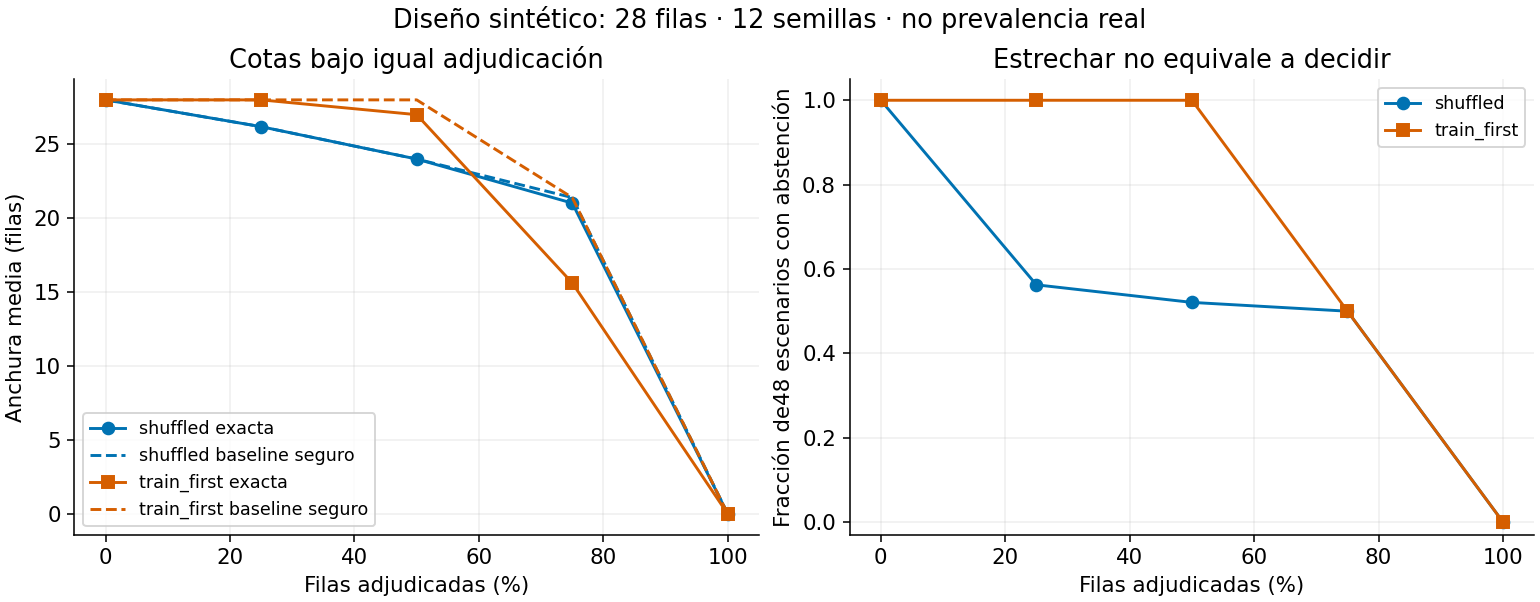

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
fig,axs=plt.subplots(1,2,figsize=(11,4.3),layout='constrained')
for sampling,color,marker in [('shuffled','#0072B2','o'),('train_first','#D55E00','s')]:
 keys=[f'{sampling}:{f}' for f in cfg['fractions']]
 axs[0].plot([100*f for f in cfg['fractions']],[s[k]['mean_width_rows'] for k in keys],color=color,marker=marker,label=sampling+' exacta')
 axs[0].plot([100*f for f in cfg['fractions']],[s[k]['mean_trivial_width_rows'] for k in keys],color=color,linestyle='--',label=sampling+' baseline seguro')
 axs[1].plot([100*f for f in cfg['fractions']],[s[k]['abstain_runs']/48 for k in keys],color=color,marker=marker,label=sampling)
axs[0].set(ylabel='Anchura media (filas)',title='Cotas bajo igual adjudicación')
axs[1].set(ylabel='Fracción de48 escenarios con abstención',title='Estrechar no equivale a decidir',ylim=(-.03,1.05))
for ax in axs:ax.set_xlabel('Filas adjudicadas (%)');ax.grid(alpha=.2);ax.legend(fontsize=9)
fig.suptitle('Diseño sintético: 28 filas · 12 semillas · no prevalencia real')
fig.savefig('results/partial1101/information.png',dpi=140)
display(Image(filename='results/partial1101/information.png'));plt.close(fig)

## Fallos y ablations negativas
Eliminar restricciones entre clases conocidas devuelve el intervalo trivial; imputar desconocidos como singleton solo da la cota inferior y puede ocultar exposición. El negativo más importante es semántico: si la adjudicación conocida está equivocada, las cotas pueden excluir la realidad. Un archivo de enlaces positivos incompletos no cumple el contrato de equivalencia completa. No se resuelve esa falta de información con más tests ni una etiqueta de seguridad.

In [5]:
# Fuera del dominio: se declaran dos identidades distintas, pero realidad una sola.
obs=[Record('a',('a',)),Record('b',('b',))]
assignment={'a':'train','b':'test'}
conditional=partial_audit(obs,obs,assignment)
real=[Record('a',('same',)),Record('b',('same',))]
actual=audit_graph(obs,real,assignment)
print('Adjudicación errónea:',conditional,'\nRealidad suministrada aparte:',actual)
assert conditional.upper_exposed_rows==0 and actual.exposed_rows==2
# Caso sin adjudicación: abstención completa, no estimación extrapolada.
print('Sin adjudicación:',partial_audit(obs,[],assignment))

Adjudicación errónea: PartialAudit(rows=2, adjudicated_rows=2, unknown_rows=0, declared_cuts=0, lower_exposed_rows=0, upper_exposed_rows=0, decision='conditional-zero') 
Realidad suministrada aparte: GraphAudit(rows=2, declared_cuts=0, adjudicated_cuts=1, exposed_rows=2, true_positive_pairs=0, false_positive_pairs=0, false_negative_pairs=1, true_negative_pairs=0)
Sin adjudicación: PartialAudit(rows=2, adjudicated_rows=0, unknown_rows=2, declared_cuts=0, lower_exposed_rows=0, upper_exposed_rows=2, decision='abstain')


## Coste y escalabilidad del auditor
Se mide solo cálculo, con tiempo y pico de memoria tracemalloc separados de instalación/I/O. Tres repeticiones por tamaño, sin intervalos poblacionales. No se ejecuta DP30 por encima de sus guardias: la escala del auditor usa split fijo y mitad adjudicada. Costes dependientes del host y del tracing.

Mediana tiempo auditor (ms) {28: 0.422558, 280: 3.071352, 2800: 34.440003, 28000: 422.482107}
Mediana pico tracemalloc (MiB) {28: 0.00439453125, 280: 0.0473785400390625, 2800: 0.4980621337890625, 28000: 4.229827880859375}


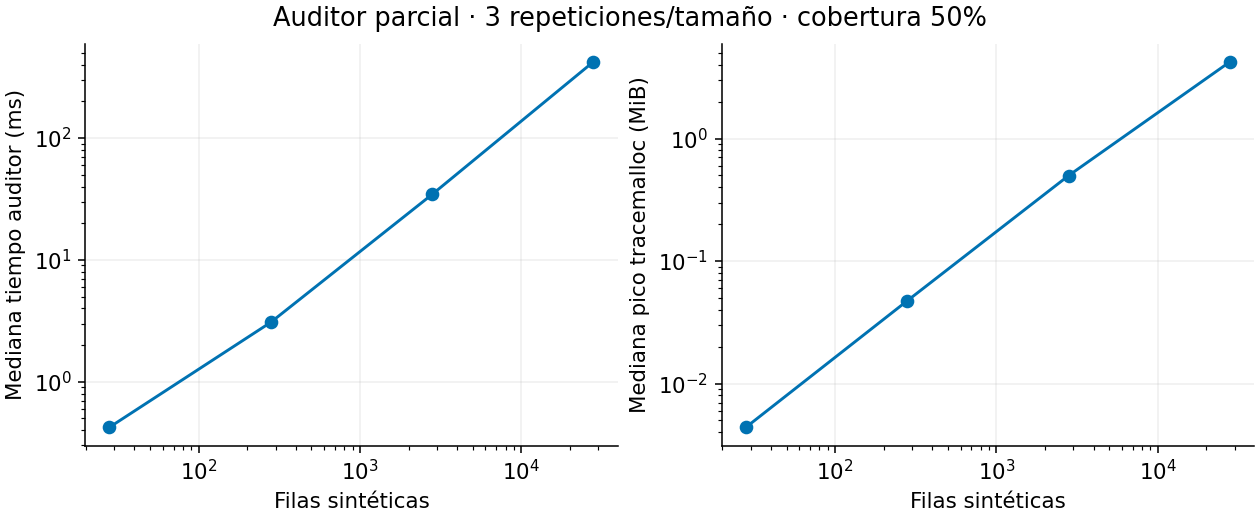

In [6]:
import statistics
scale=json.loads(Path('results/partial1101/scale.json').read_text())
sizes=sorted({r['rows'] for r in scale})
fig,axs=plt.subplots(1,2,figsize=(9,3.7),layout='constrained')
for ax,field,factor,label in [(axs[0],'elapsed_ns',1e6,'Mediana tiempo auditor (ms)'),(axs[1],'peak_bytes',1024**2,'Mediana pico tracemalloc (MiB)')]:
 values=[statistics.median(r[field]/factor for r in scale if r['rows']==n) for n in sizes]
 ax.loglog(sizes,values,marker='o',color='#0072B2');ax.set(xlabel='Filas sintéticas',ylabel=label);ax.grid(alpha=.2)
 print(label,dict(zip(sizes,values)))
fig.suptitle('Auditor parcial · 3 repeticiones/tamaño · cobertura 50%')
fig.savefig('results/partial1101/cost.png',dpi=140)
display(Image(filename='results/partial1101/cost.png'));plt.close(fig)

## Discusión calculada y siguientes decisiones
Construimos una API modular de cotas y una explicación de por qué adjudicación parcial no implica ausencia de fuga. Podemos aprovechar información incompleta y cuantificar su ambigüedad sin inventar etiquetas faltantes. El caso completo recupera31; el caso sin adjudicación se abstiene. El resultado técnico es local y condicionado; no certifica calidad de adjudicación ni validez temporal, no evalúa modelos ni AUC.

Continuar con origen/fecha/equivalencia adjudicada auditables. Ajustar si solo existen enlaces positivos: cambiar contrato y mantener intervalos conservadores. Cerrar cualquier uso que convierta conditional-zero en garantía de independencia empírica. Madurez experimental, ejecución local; revisión independiente/publicación/CI se registran aparte. Ejecución real IPython secuencial en proceso, no kernel aislado ni frontend Jupyter completo. Figuras inspeccionadas como PNG.

Fuentes primarias verificadas1nov2026: Binette/Steorts arXiv2008.04443 (resumen, alcance honesto); Tamer2010 DOI10.1146/annurev.economics.050708.143401 (resumen/concepto, no atribución de fórmula); Kapoor/Narayanan2023 textoPMC; sklearn pair_confusion_matrix; NetworkX connected_components. Matriz prior_art1101.md y referencias.bib.